# CSIP Module 09: Model Evaluation & Explainability (SHAP & Calibration)
**Core Strategy & Intelligence Platform (CSIP) — Modul Analisis Evaluasi & Daya Jelas Model**

### Catatan Kontrak Prediksi & Estimand (Prediction Contract Scope):
Model klasifikasi ketidakpuasan awal (`E1_checkout_retrospective_conditional`) yang dievaluasi merupakan **model risiko bersyarat retrospektif** $\mathbb{P}(\text{Negative Review} = 1 \mid X_{t_0}, \text{Delivered}=1, \text{Review Observed}=1)$. Atribusi fitur global (TreeSHAP) mencerminkan dampak keterlambatan pengiriman dan waktu transit pada pesanan yang sampai ke tangan pembeli. Model ini secara eksplisit bukan model pembatalan pesanan atau checkout abandonment.


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
sys.path.insert(0, str(REPO_ROOT / 'src'))

import json
import pandas as pd
from IPython.display import Image, display

# Load Explainability Report
report_path = REPO_ROOT / 'artifacts' / 'reports' / 'model_explainability.json'
with open(report_path, 'r') as f:
    report = json.load(f)

print(f"Target: {report['target']}")
print(f"Champion Model: {report['champion_model']}")

Target: negative_review_flag
Champion Model: B3 LightGBM


## 1. Global Feature Attribution (SHAP TreeExplainer)
We inspect the top features driving negative review risk according to mean absolute SHAP values.

,rank,feature,mean_abs_shap
0,1,delivery_delay_days,0.305808
1,2,delivery_lead_time_days,0.225169
2,3,item_count,0.208579
3,4,estimated_lead_time_days,0.074026
4,5,total_freight,0.070134
5,6,distance_x_weight,0.066525
6,7,payment_installments_max,0.042351
7,8,seller_buyer_distance_km,0.041006
8,9,approval_lag_hours,0.029752
9,10,freight_ratio,0.027718


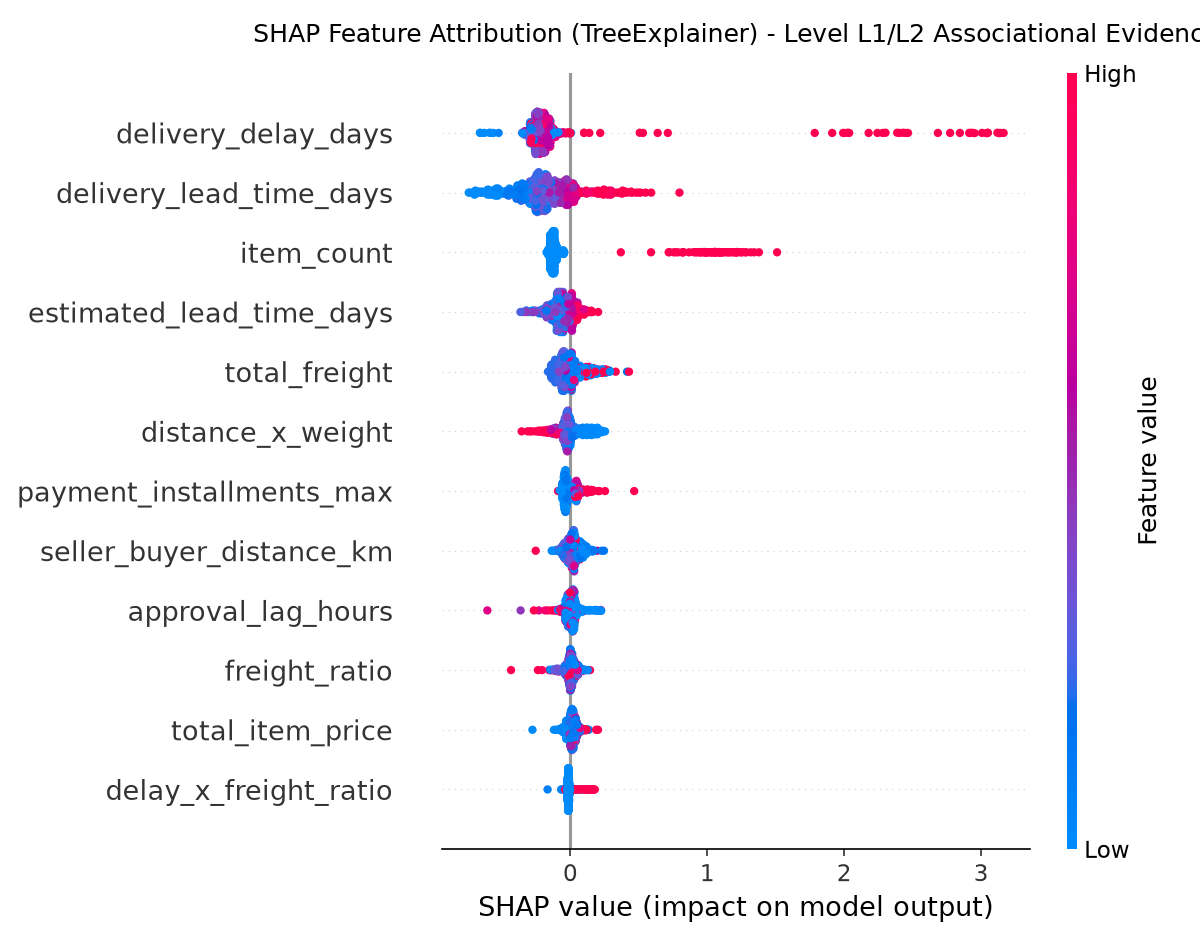

In [2]:
shap_df = pd.DataFrame(report['shap_attribution']['top_features'])
display(shap_df.head(10))

display(Image(filename=str(REPO_ROOT / 'artifacts' / 'reports' / 'figures' / 'shap_summary_plot.png')))

## 2. Probability Calibration & Reliability Diagram
Under severe class imbalance, predicted probabilities are often uncalibrated.
We inspect the out-of-time test set calibration before and after Platt scaling.

Calibration Metrics (Locked Out-of-Time Test Split):
- Raw Brier Score: 0.1375
- Calibrated Brier Score: 0.0762 (Improvement: 44.59%)
- Raw ECE: 0.2355
- Calibrated ECE: 0.0070


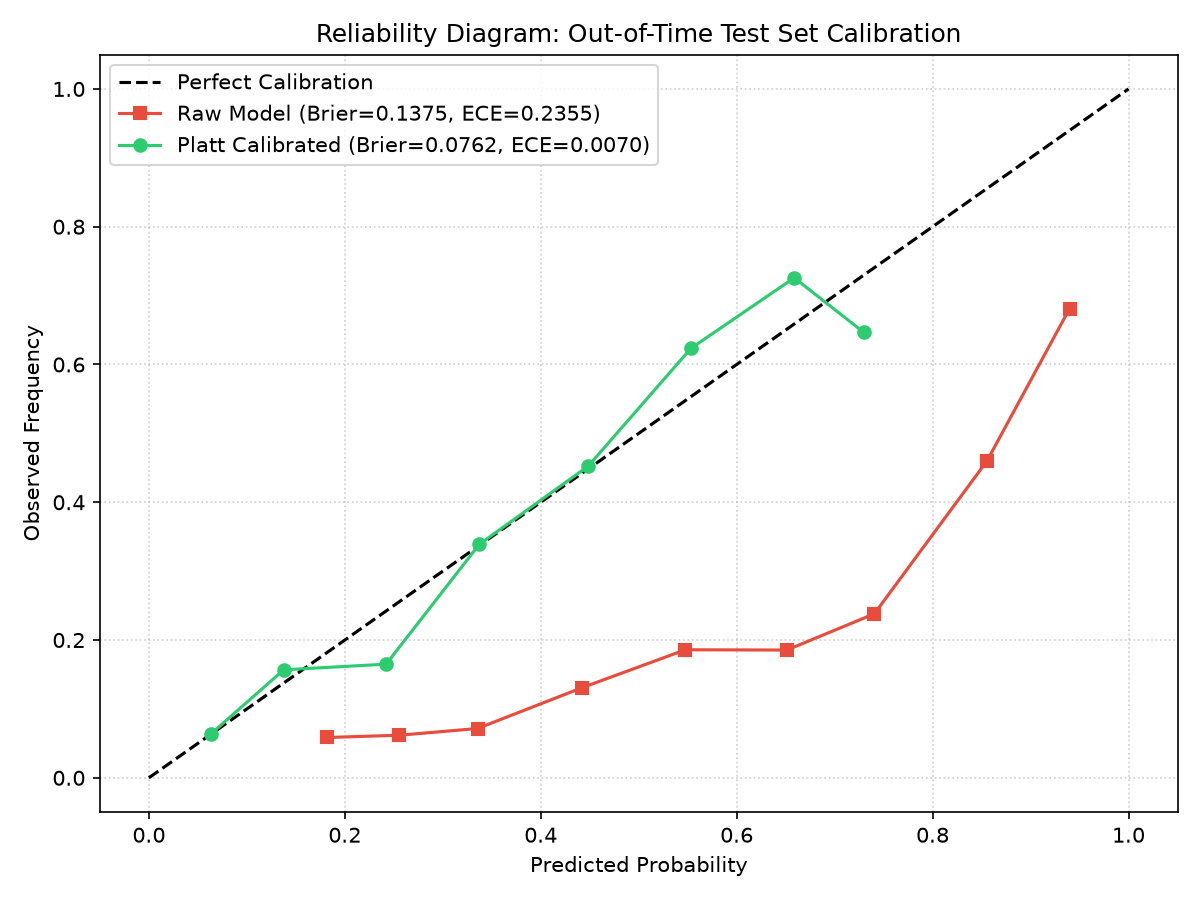

In [3]:
calib = report['calibration']
print('Calibration Metrics (Locked Out-of-Time Test Split):')
print(f"- Raw Brier Score: {calib['uncalibrated_brier']:.4f}")
print(f"- Calibrated Brier Score: {calib['calibrated_brier']:.4f} (Improvement: {calib['brier_improvement_pct']:.2f}%)")
print(f"- Raw ECE: {calib['uncalibrated_ece']:.4f}")
print(f"- Calibrated ECE: {calib['calibrated_ece']:.4f}")

display(Image(filename=str(REPO_ROOT / 'artifacts' / 'reports' / 'figures' / 'calibration_curves.png')))